In [1]:
from neural_recording_chain.data_rate import raw_data_rate, spike_data_rate

# the published Neuralink N1 numbers
n1_rate = raw_data_rate(n_electrodes=1024, sampling_rate_Hz=20000, n_bits=10)
print("Neuralink N1:", n1_rate / 1_000_000, "million bits per second")

# our own chain: 8 bits at 20,000 samples per second
electrode_counts = [1, 100, 1000, 10000]

for n_electrodes in electrode_counts:
    rate = raw_data_rate(n_electrodes, sampling_rate_Hz=20000, n_bits=8)
    print(n_electrodes, "electrodes:", rate / 1_000_000, "million bits per second")

Neuralink N1: 204.8 million bits per second
1 electrodes: 0.16 million bits per second
100 electrodes: 16.0 million bits per second
1000 electrodes: 160.0 million bits per second
10000 electrodes: 1600.0 million bits per second


In [2]:
detections_in_60_s = 254
spikes_per_second = detections_in_60_s / 60
bits_per_spike = 32

for n_electrodes in electrode_counts:
    everything = raw_data_rate(n_electrodes, sampling_rate_Hz=20000, n_bits=8)
    spikes_only = spike_data_rate(n_electrodes, spikes_per_second, bits_per_spike)
    times_smaller = everything / spikes_only

    print(n_electrodes, "electrodes | everything:", everything, "| spikes only:", round(spikes_only),
          "| times smaller:", round(times_smaller))

1 electrodes | everything: 160000 | spikes only: 135 | times smaller: 1181
100 electrodes | everything: 16000000 | spikes only: 13547 | times smaller: 1181
1000 electrodes | everything: 160000000 | spikes only: 135467 | times smaller: 1181
10000 electrodes | everything: 1600000000 | spikes only: 1354667 | times smaller: 1181


electrodes that fit, sending everything: 6
electrodes that fit, sending spikes only: 7381


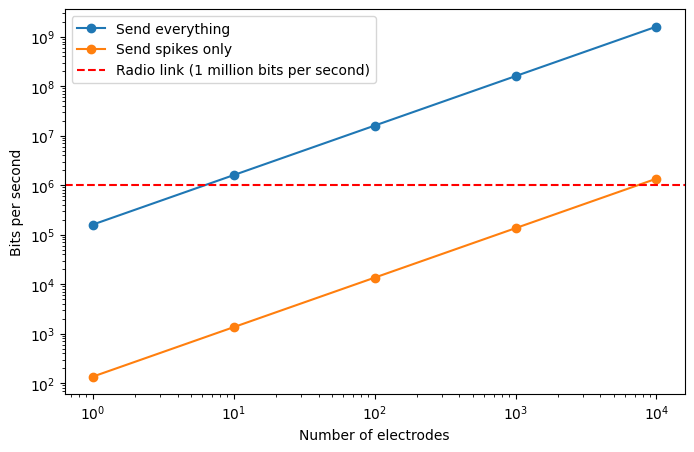

In [3]:
import matplotlib.pyplot as plt

link_capacity = 1_000_000   # bits per second, the published figure for Neuralink's N1

per_electrode_everything = raw_data_rate(1, sampling_rate_Hz=20000, n_bits=8)
per_electrode_spikes = spike_data_rate(1, spikes_per_second, bits_per_spike)

print("electrodes that fit, sending everything:", int(link_capacity / per_electrode_everything))
print("electrodes that fit, sending spikes only:", int(link_capacity / per_electrode_spikes))

counts = [1, 10, 100, 1000, 10000]
everything_rates = []
spikes_only_rates = []

for n_electrodes in counts:
    everything_rates.append(raw_data_rate(n_electrodes, sampling_rate_Hz=20000, n_bits=8))
    spikes_only_rates.append(spike_data_rate(n_electrodes, spikes_per_second, bits_per_spike))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(counts, everything_rates, "o-", label="Send everything")
ax.plot(counts, spikes_only_rates, "o-", label="Send spikes only")
ax.axhline(link_capacity, color="red", linestyle="--", label="Radio link (1 million bits per second)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of electrodes")
ax.set_ylabel("Bits per second")
ax.legend()
plt.show()